# Experimentos de nubes CCSN (11 clases, RGB 256×256)

Este notebook usa los módulos del proyecto y **no descarga imágenes**. Ejecuta primero EDA, curación y preparación desde el README. Separa train/validation de la evaluación final en test, como en el repositorio del profesor.


## 0. Preparacion de imagenes, EDA y demas procesos antes de primer entrenamiento.


### Determinacion de modelo Base

In [20]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir() and (ROOT.parent / "src").is_dir():
    ROOT = ROOT.parent

SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))


In [ ]:
import pandas as pd
import numpy as np
from clouds_cnn.config import ExperimentConfig
from clouds_cnn.data import make_split_loader, load_dataset_stats
from clouds_cnn.models import CloudCNN
from clouds_cnn.plots import plot_runs_comparison, plot_confusion_matrix
from clouds_cnn.inspection import capture_feature_maps
from clouds_cnn.utils import get_device
from clouds_cnn.eda import run_eda

config = ExperimentConfig()
assert config.num_classes == 11 and config.image_size == 256
print(config)


ExperimentConfig(run_name='baseline', split_seed=2026, train_seed=2026, deterministic=False, num_classes=11, image_size=256, center_crop=None, batch_size=32, num_workers=0, use_batchnorm=False, dropout_p=0.0, learning_rate=0.001, weight_decay=0.0, epochs=30, device_preference='auto', data_root=WindowsPath('C:/Users/Dany/Documents/Codigo de Matematicas cualquiera/Sistemas Inteligentes II/CNN-Nubes-Corte-II_FInal/data/processed'), output_root=WindowsPath('C:/Users/Dany/Documents/Codigo de Matematicas cualquiera/Sistemas Inteligentes II/CNN-Nubes-Corte-II_FInal/outputs'), mlflow_experiment_name='clouds-cnn-from-scratch')


### Comprobar ruta raiz y designar rutas de imagenes

In [21]:
ROOT = Path(r"C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal")
RAW = ROOT / "data" / "raw"
CURATED = ROOT / "data" / "curated"
PROCESSED = ROOT / "data" / "processed"

### Chequeo de clases en la carpeta data\raw

In [23]:

CLASSES = (
    "Ac", "As", "Cb", "Cc", "Ci", "Cs",
    "Ct", "Cu", "Ns", "Sc", "St"
)

EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

counts = {
    name: sum(
        file.is_file() and file.suffix.lower() in EXTENSIONS
        for file in (RAW / name).rglob("*")
    )
    for name in CLASSES
}

for name, count in counts.items():
    print(f"{name}: {count} imágenes")

assert all(count > 0 for count in counts.values()), (
    "Faltan imágenes en una o más clases de data/raw."
)

print("Total:", sum(counts.values()))


Ac: 221 imágenes
As: 188 imágenes
Cb: 242 imágenes
Cc: 268 imágenes
Ci: 139 imágenes
Cs: 287 imágenes
Ct: 200 imágenes
Cu: 182 imágenes
Ns: 274 imágenes
Sc: 340 imágenes
St: 202 imágenes
Total: 2543


### Eda para los datos iniciales

EDA finalizado correctamente.
Reportes guardados en: C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal\repositorio\eda
brightness_contrast.png
class_balance.csv
class_balance.png
class_examples.png
curated
eda_summary.json
exact_duplicates.csv
image_inventory.csv
image_properties.csv

Gráfico: brightness_contrast.png


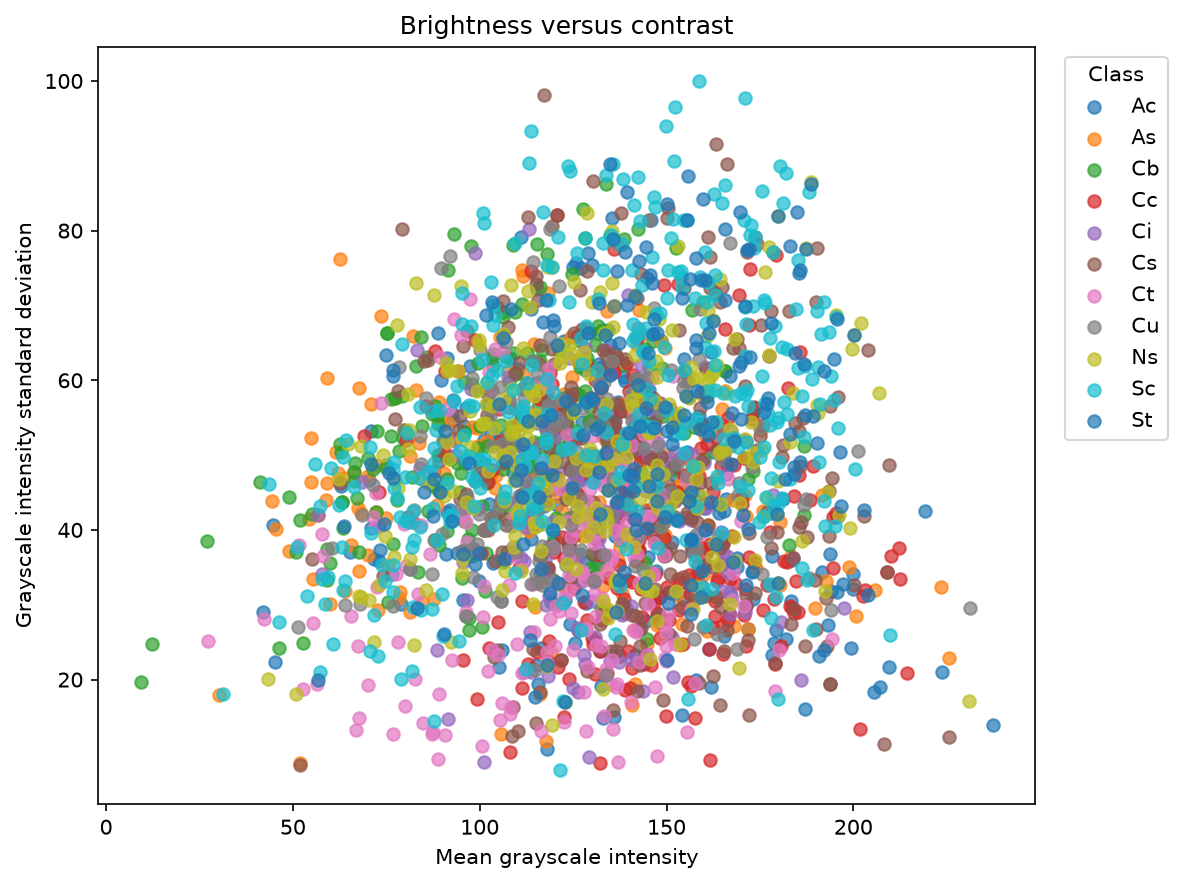


Gráfico: class_balance.png


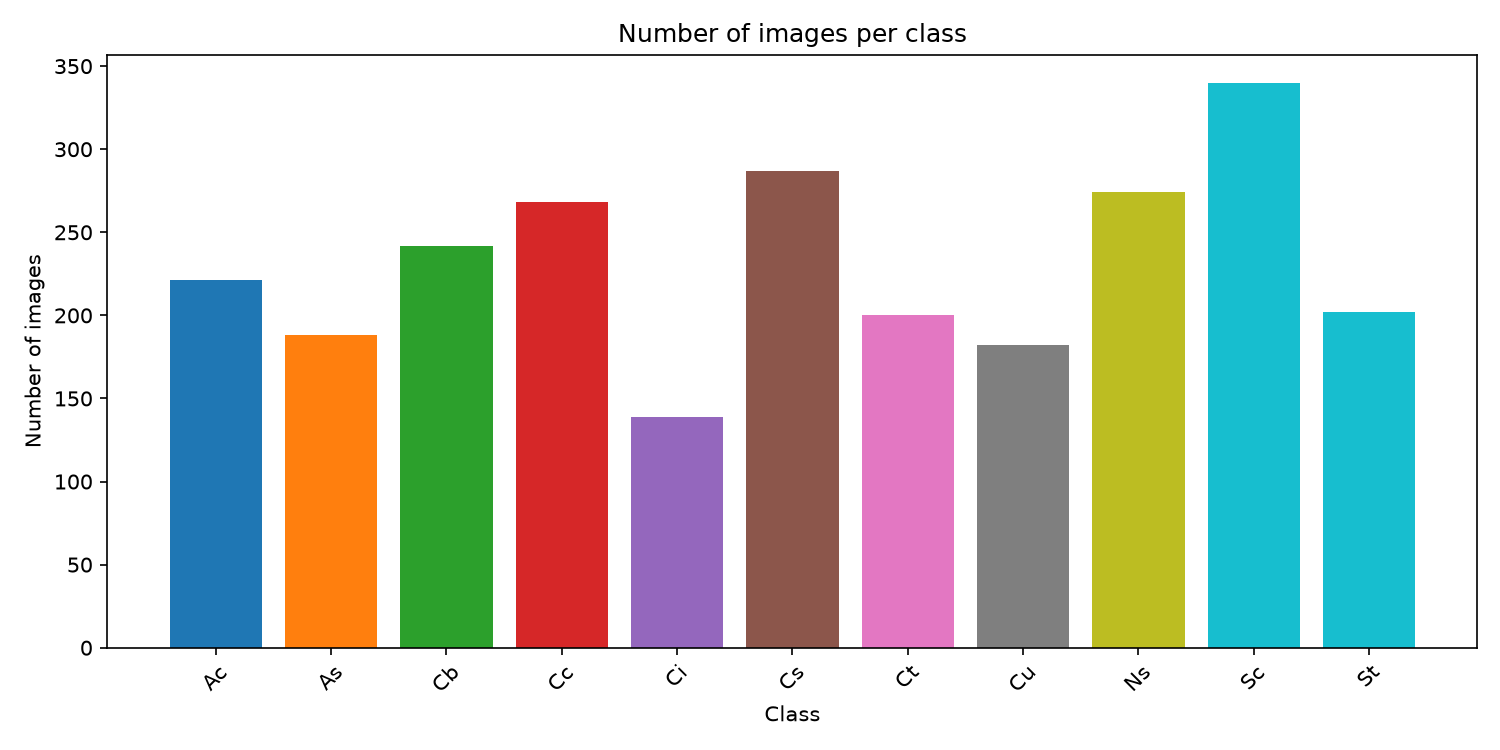


Gráfico: class_examples.png


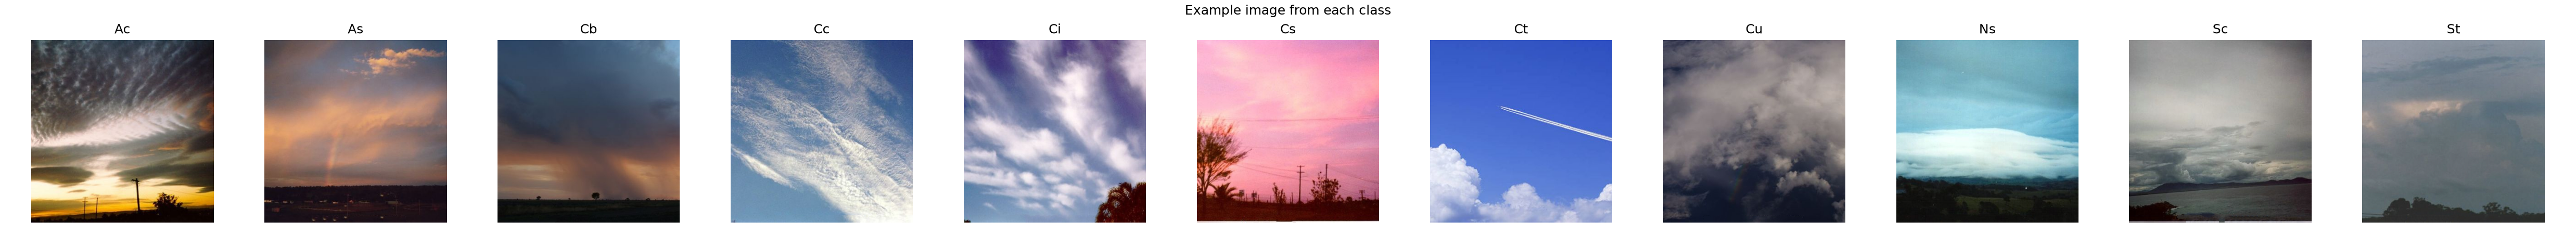

In [24]:
from IPython.display import display, Image
from clouds_cnn.eda import run_eda

EDA_DIR = ROOT / "repositorio" / "eda"

# Crear automáticamente las carpetas.
EDA_DIR.mkdir(parents=True, exist_ok=True)

# Ejecutar todas las operaciones de eda.py.
eda_summary = run_eda(
    data_dir=RAW,
    output_dir=EDA_DIR,
    make_plots=True,
)

print("EDA finalizado correctamente.")
print("Reportes guardados en:", EDA_DIR)

# Mostrar los archivos generados.
for archivo in sorted(EDA_DIR.iterdir()):
    print(archivo.name)

# Visualizar los gráficos en Jupyter.
for grafico in sorted(EDA_DIR.glob("*.png")):
    print("\nGráfico:", grafico.name)
    display(Image(filename=str(grafico)))



### Limpieza de datos

In [25]:

from clouds_cnn.curate_dataset import curate_dataset

CURATION_DIR = ROOT / "repositorio" / "curation"

# Crear el directorio de reportes.
CURATION_DIR.mkdir(parents=True, exist_ok=True)

# Ejecutar la curación completa.
curation_summary = curate_dataset(
    input_dir=RAW,
    output_dir=CURATED,
    report_dir=CURATION_DIR,
    overwrite=True,
)

print("Curación finalizada.")
print(curation_summary)


Curación finalizada.
{'source_directory': 'C:\\Users\\Dany\\Documents\\Codigo de Matematicas cualquiera\\Sistemas Inteligentes II\\CNN-Nubes-Corte-II_FInal\\data\\raw', 'curated_directory': 'C:\\Users\\Dany\\Documents\\Codigo de Matematicas cualquiera\\Sistemas Inteligentes II\\CNN-Nubes-Corte-II_FInal\\data\\curated', 'total_images_found': 2543, 'images_kept': 2523, 'images_excluded': 20, 'excluded_by_reason': {'cross_class_duplicate_label_unresolved': 6, 'redundant_same_class_duplicate': 14}, 'unresolved_cross_class_duplicate_groups': 3, 'curated_images_by_class': {'Ac': 219, 'As': 185, 'Cb': 236, 'Cc': 265, 'Ci': 139, 'Cs': 286, 'Ct': 200, 'Cu': 177, 'Ns': 274, 'Sc': 340, 'St': 202}, 'policy': {'same_class_duplicates': 'Keep one deterministic copy.', 'cross_class_duplicates': 'Exclude every copy until the correct label is verified.', 'unreadable_images': 'Exclude and record the error.', 'raw_dataset': 'Never modified.'}}


### Segundo Eda al data curado


EDA de imágenes curadas finalizado.
Reportes guardados en: C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal\reports\eda_curated
{'dataset_directory': 'C:\\Users\\Dany\\Documents\\Codigo de Matematicas cualquiera\\Sistemas Inteligentes II\\CNN-Nubes-Corte-II_FInal\\data\\curated', 'report_directory': 'C:\\Users\\Dany\\Documents\\Codigo de Matematicas cualquiera\\Sistemas Inteligentes II\\CNN-Nubes-Corte-II_FInal\\reports\\eda_curated', 'properties': {'total_images': 2523, 'readable_images': 2523, 'unreadable_images': 0, 'dimension_counts': {'256x256': 207, '400x400': 2316}, 'color_mode_counts': {'RGB': 2523}, 'brightness': {'mean': 131.364, 'median': 132.7628, 'minimum': 9.2296, 'maximum': 237.3431, 'standard_deviation': 33.9196}, 'contrast': {'mean': 47.0527, 'median': 46.8344, 'minimum': 7.9408, 'maximum': 100.0038, 'standard_deviation': 15.9082}}, 'class_balance': [{'class_name': 'Ac', 'image_count': 219, 'percentage': 8.6801,

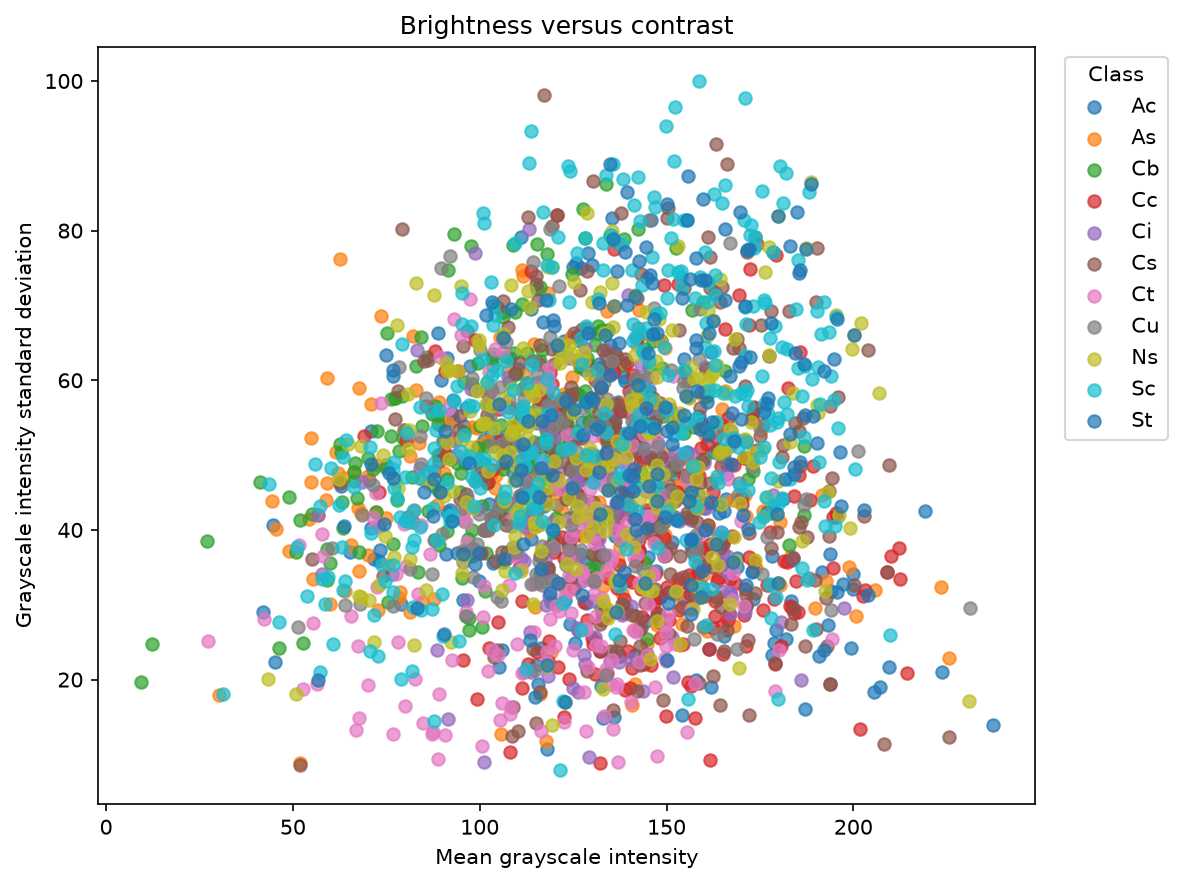


Gráfico: class_balance.png


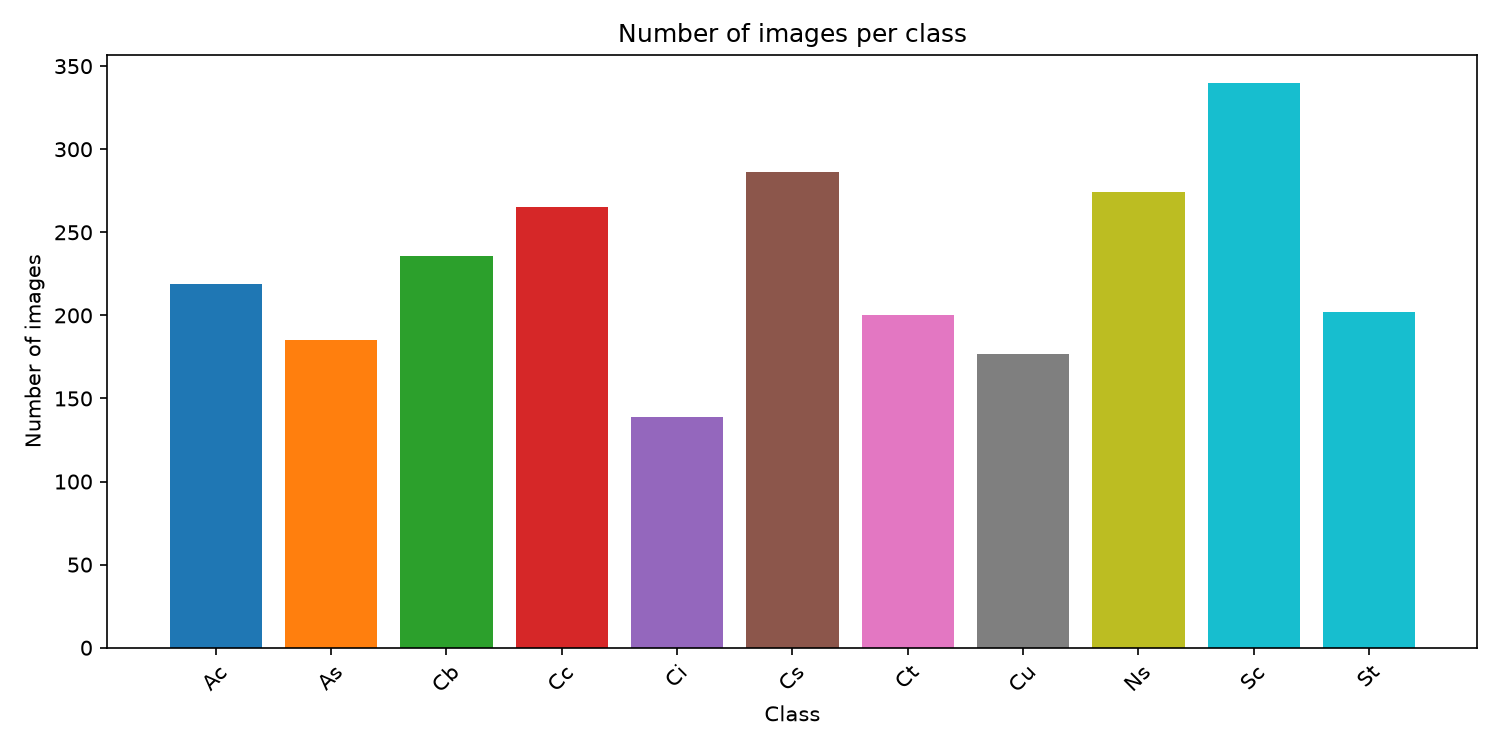


Gráfico: class_examples.png


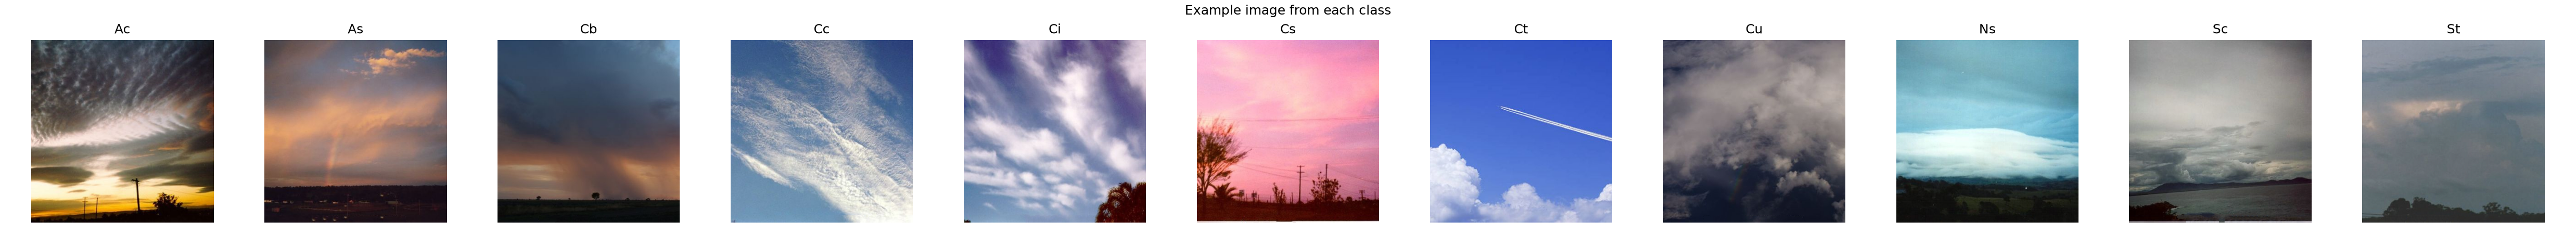

In [26]:
EDA_CURATED = ROOT / "reports" / "eda_curated"

# Crear el directorio para el segundo EDA.
EDA_CURATED.mkdir(parents=True, exist_ok=True)

# Ejecutar todo eda.py sobre las imágenes curadas.
eda_curated_summary = run_eda(
    data_dir=CURATED,
    output_dir=EDA_CURATED,
    make_plots=True,
)

print("EDA de imágenes curadas finalizado.")
print("Reportes guardados en:", EDA_CURATED)
print(eda_curated_summary)

# Mostrar los archivos generados.
for archivo in sorted(EDA_CURATED.rglob("*")):
    if archivo.is_file():
        print(archivo.relative_to(EDA_CURATED))

# Visualizar los gráficos generados.
for grafico in sorted(EDA_CURATED.rglob("*.png")):
    print("\nGráfico:", grafico.name)
    display(Image(filename=str(grafico)))

### Comparación de EDA

In [27]:
# Obtener la distribución original.
original = pd.DataFrame(
    eda_summary["class_balance"]
)[["class_name", "image_count"]]

# 2. Obtener la distribución después de la curación.
curado = pd.DataFrame(
    eda_curated_summary["class_balance"]
)[["class_name", "image_count"]]

# Comparar ambos conjuntos por clase.
comparacion = original.merge(
    curado,
    on="class_name",
    how="outer",
    suffixes=("_original", "_curado")
).fillna(0)

# Renombrar las columnas.
comparacion = comparacion.rename(columns={
    "class_name": "Clase",
    "image_count_original": "Original",
    "image_count_curado": "Curado",
})

# Calcular las imágenes excluidas.
comparacion["Excluidas"] = (
    comparacion["Original"] - comparacion["Curado"]
)

# Mostrar los resultados.
display(comparacion)

# Mostrar los totales.
print("\nTotal original:", int(comparacion["Original"].sum()))
print("Total curado:", int(comparacion["Curado"].sum()))
print("Total excluido:", int(comparacion["Excluidas"].sum()))



,Clase,Original,Curado,Excluidas
0,Ac,221,219,2
1,As,188,185,3
2,Cb,242,236,6
3,Cc,268,265,3
4,Ci,139,139,0
5,Cs,287,286,1
6,Ct,200,200,0
7,Cu,182,177,5
8,Ns,274,274,0
9,Sc,340,340,0



Total original: 2543
Total curado: 2523
Total excluido: 20


### Separacion por train | val | test

In [30]:
from clouds_cnn.preparation import prepare

PREPARATION_DIR = ROOT / "reports" / "preparation"

print("¿Existe la carpeta?", PROCESSED.exists())

if PROCESSED.exists():
    print("Contenido de data/processed:")
    for item in PROCESSED.iterdir():
        print(" -", item.name)
else:
    print("La carpeta todavía no existe.")

# Ejecutar únicamente si la carpeta de salida no existe.
if not PROCESSED.exists():
    stats = prepare(
        source=CURATED,
        output=PROCESSED,
        split_seed=config.split_seed,
        image_size=config.image_size,
        center_crop=config.center_crop,
        num_workers=config.num_workers,
        overwrite=False,
    )

    print("Preparación finalizada.")
    print("Directorio de salida:", PROCESSED)
    print(stats)
else:
    print(
        "No se ejecutó la preparación porque la carpeta ya existe. "
        "Revisa su contenido antes de decidir si debes regenerarla."
    )

¿Existe la carpeta? True
Contenido de data/processed:
 - dataset_stats.json
 - manifest.csv
 - test
 - train
 - val
No se ejecutó la preparación porque la carpeta ya existe. Revisa su contenido antes de decidir si debes regenerarla.


## 1. Entrenar el modelo basline


In [31]:
from clouds_cnn.experiment import run_experiment

# 1. Verificar que los datos están preparados.
assert (config.data_root / "dataset_stats.json").is_file(), (
    "Prepara primero las imágenes con clouds_cnn.preparation."
)

# 2. Cargar y verificar las clases.
stats = load_dataset_stats(config.data_root)

assert len(stats["class_to_label"]) == config.num_classes, (
    "El número de clases no coincide con la configuración."
)

# 3. Mostrar la configuración del baseline.
print("Configuración del baseline:")
print(config)

print("\nClases:")
print(stats["class_to_label"])

# 4. Entrenar un único modelo con la configuración existente.
resultado_baseline = run_experiment(config)


Configuración del baseline:
ExperimentConfig(run_name='baseline', split_seed=2026, train_seed=2026, deterministic=False, num_classes=11, image_size=256, center_crop=None, batch_size=32, num_workers=0, use_batchnorm=False, dropout_p=0.0, learning_rate=0.001, weight_decay=0.0, epochs=30, device_preference='auto', data_root=WindowsPath('C:/Users/Dany/Documents/Codigo de Matematicas cualquiera/Sistemas Inteligentes II/CNN-Nubes-Corte-II_FInal/data/processed'), output_root=WindowsPath('C:/Users/Dany/Documents/Codigo de Matematicas cualquiera/Sistemas Inteligentes II/CNN-Nubes-Corte-II_FInal/outputs'), mlflow_experiment_name='clouds-cnn-from-scratch')

Clases:
{'Ac': 0, 'As': 1, 'Cb': 2, 'Cc': 3, 'Ci': 4, 'Cs': 5, 'Ct': 6, 'Cu': 7, 'Ns': 8, 'Sc': 9, 'St': 10}
Época   1/30 | train loss 2.2631 acc 0.1806 | val loss 2.1281 acc 0.2090 | 151.7s *
Época   2/30 | train loss 2.1158 acc 0.2310 | val loss 2.0699 acc 0.2196 | 127.0s *
Época   3/30 | train loss 2.0596 acc 0.2752 | val loss 2.0667 acc 0.

## 3. Mapas de representación, curvas, matrices y métricas de validación

El criterio principal es `val_macro_f1`, calculado con el mejor checkpoint de cada run.


Clase real: Ac
Predicción: Ac


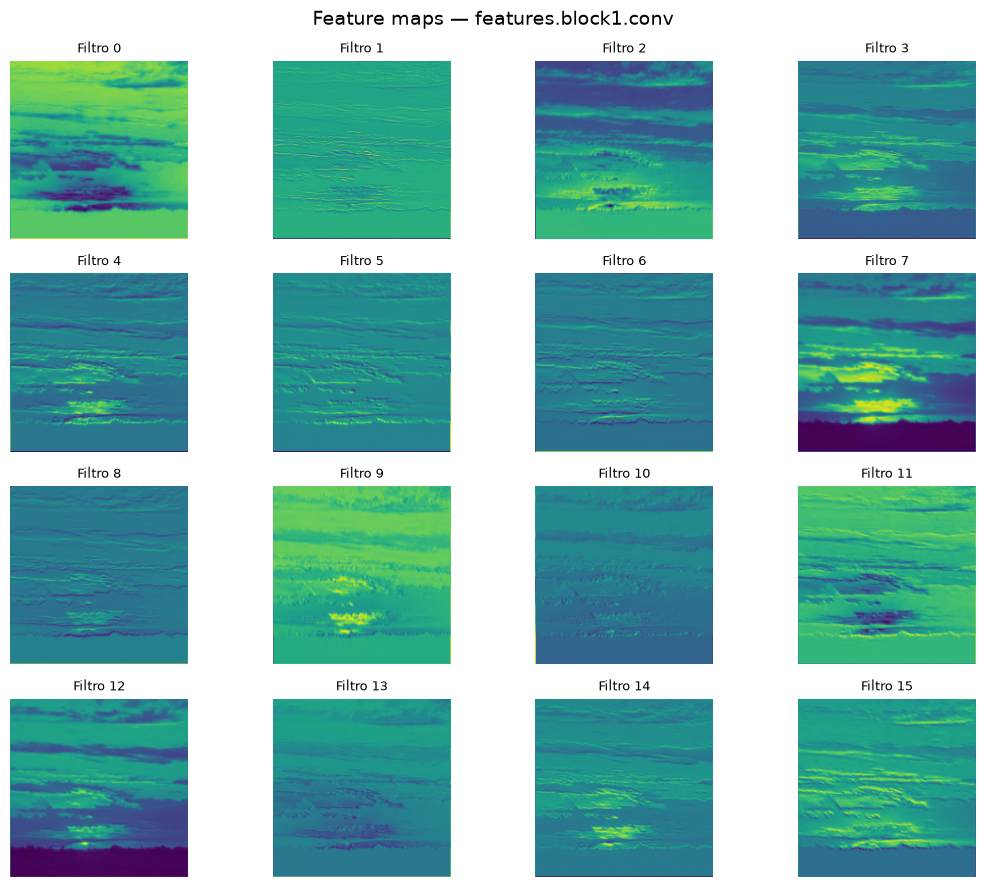

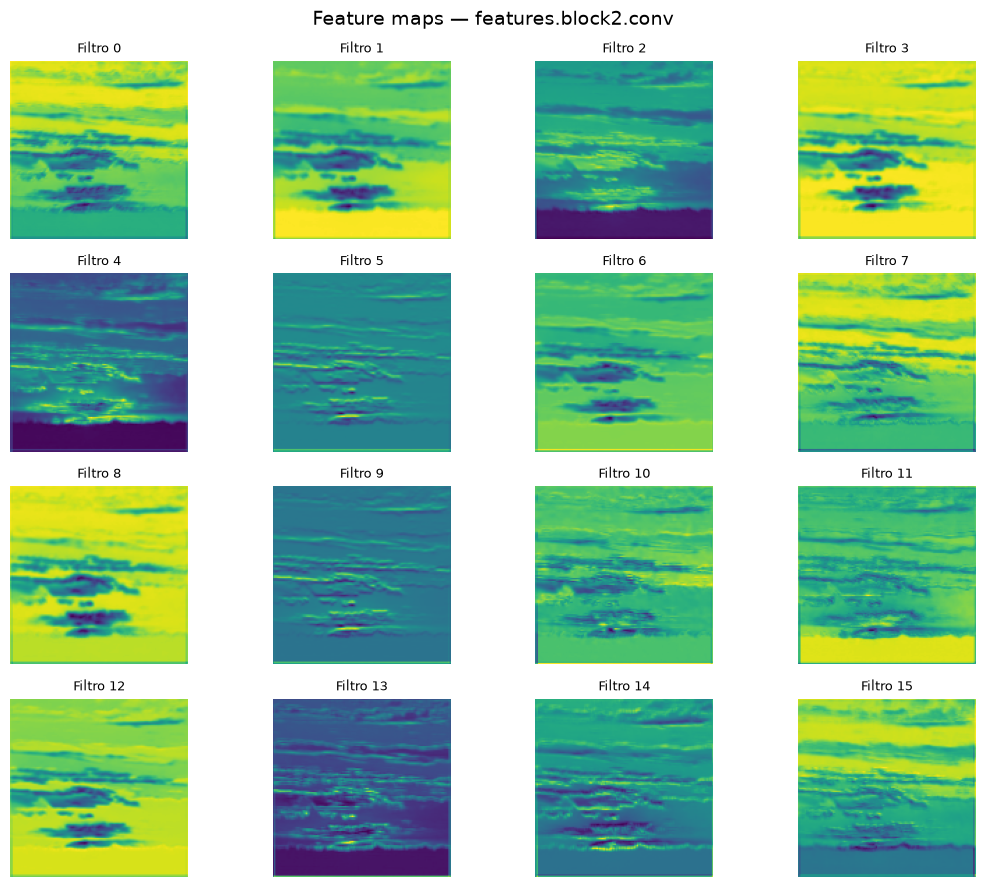

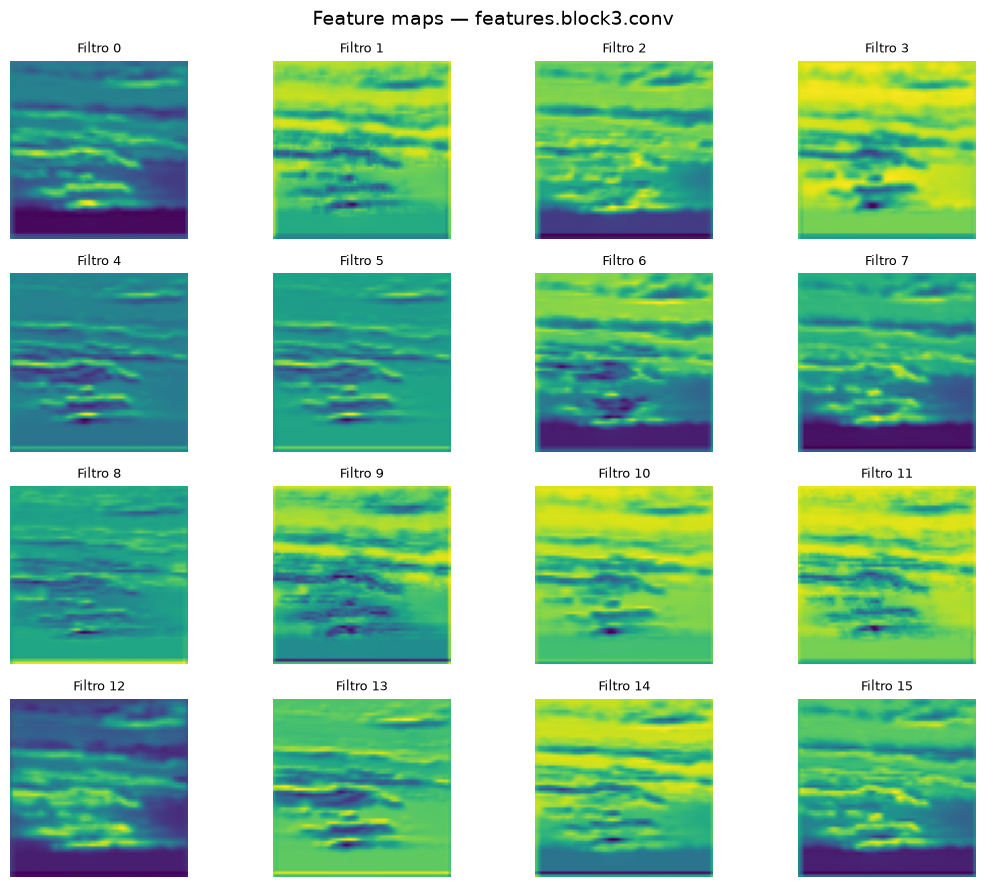

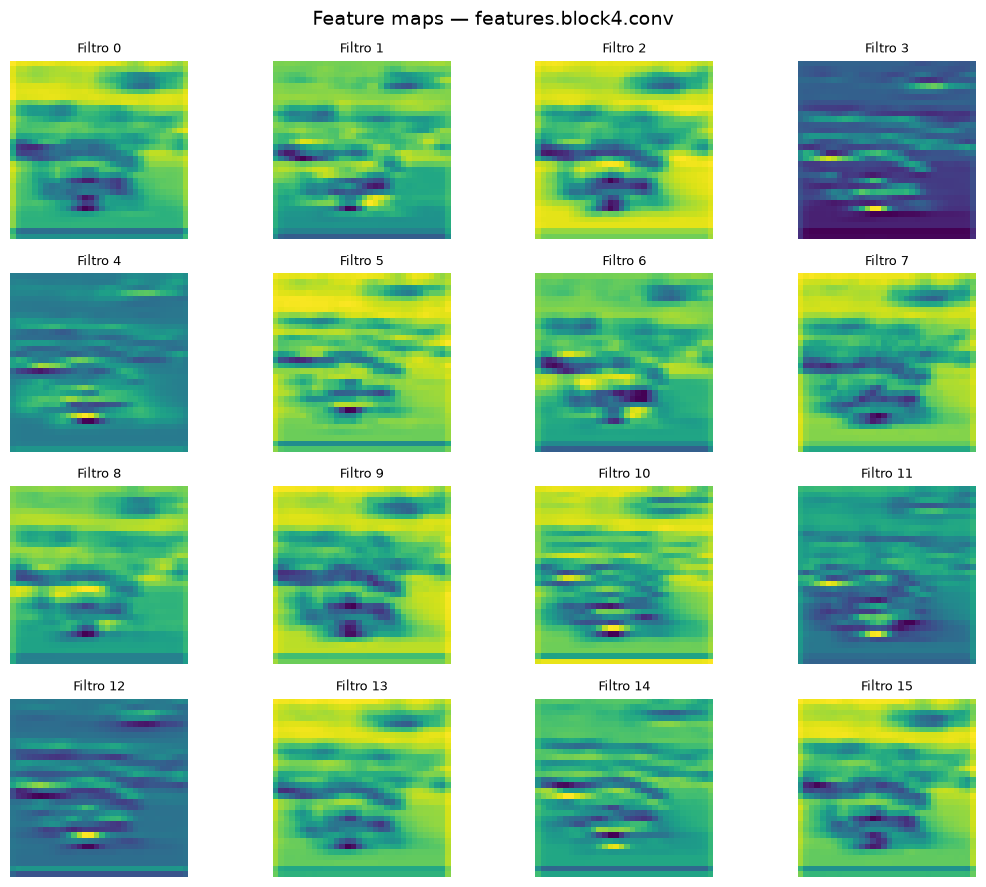


Feature maps guardados en:
C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal\outputs\feature_maps


In [32]:

import ast
import inspect
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from clouds_cnn.experiment import run_experiment
from clouds_cnn.data import make_split_loader

# Recuperar el constructor de la CNN.
codigo = inspect.getsource(run_experiment)
arbol = ast.parse(codigo)

asignaciones = [
    nodo.value
    for nodo in ast.walk(arbol)
    if isinstance(nodo, ast.Assign)
    and isinstance(nodo.value, ast.Call)
    and any(
        isinstance(t, ast.Name) and t.id == "model"
        for t in nodo.targets
    )
]

if len(asignaciones) != 1:
    raise RuntimeError(
        "No se identificó un único constructor de la CNN."
    )

# Reconstruir la arquitectura.
expresion = ast.Expression(body=asignaciones[0])
ast.fix_missing_locations(expresion)

# Reconstruir la CNN utilizando CPU.
device = torch.device("cpu")

contexto = dict(run_experiment.__globals__)
contexto["config"] = config
contexto["device"] = device

model = eval(
    compile(expresion, "<constructor>", "eval"),
    contexto
)

model = model.to(device)
# 3. Cargar los pesos del baseline.
checkpoint = torch.load(
    resultado_baseline.checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Seleccionar una imagen de validación.
val_loader = make_split_loader(config, "val")
imagenes, etiquetas = next(iter(val_loader))

imagen = imagenes[0:1].to(device)
clase_real = resultado_baseline.class_names[
    etiquetas[0].item()
]

# Capturar las salidas convolucionales.
activaciones = {}
hooks = []

for nombre, capa in model.named_modules():
    if isinstance(capa, nn.Conv2d):

        def capturar(modulo, entrada, salida, nombre=nombre):
            activaciones[nombre] = salida.detach().cpu()

        hooks.append(
            capa.register_forward_hook(capturar)
        )

# Realizar una inferencia sin entrenamiento.
try:
    with torch.no_grad():
        logits = model(imagen)
finally:
    for hook in hooks:
        hook.remove()

prediccion = resultado_baseline.class_names[
    logits.argmax(dim=1).item()
]

print("Clase real:", clase_real)
print("Predicción:", prediccion)

# Crear la carpeta de resultados.
salida = Path(config.output_root) / "feature_maps"
salida.mkdir(parents=True, exist_ok=True)

# Visualizar y guardar los feature maps.
for nombre, activacion in activaciones.items():

    mapas = activacion[0]
    cantidad = min(16, mapas.shape[0])

    fig, axes = plt.subplots(
        4, 4, figsize=(11, 9)
    )

    for i, ax in enumerate(axes.flat):
        ax.axis("off")

        if i < cantidad:
            ax.imshow(
                mapas[i].numpy(),
                cmap="viridis"
            )
            ax.set_title(
                f"Filtro {i}",
                fontsize=9
            )

    fig.suptitle(
        f"Feature maps — {nombre}",
        fontsize=14
    )

    plt.tight_layout()

    archivo = salida / (
        f"{nombre.replace('.', '_')}.png"
    )

    fig.savefig(
        archivo,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("\nFeature maps guardados en:")
print(salida)



MÉTRICAS GENERALES


,particion,loss,accuracy,accuracy_%,macro_f1
0,train,1.3620,52.66%,52.66,48.11%
1,val,1.7990,37.04%,37.04,32.74%



MÉTRICAS POR CLASE — TRAIN


,clase,muestras,aciertos,accuracy_clase,precision,recall,f1
0,Ac,153,45,29.41%,61.64%,29.41%,39.82%
1,As,130,48,36.92%,53.33%,36.92%,43.64%
2,Cb,165,125,75.76%,57.60%,75.76%,65.45%
3,Cc,186,125,67.20%,50.00%,67.20%,57.34%
4,Ci,97,34,35.05%,46.58%,35.05%,40.00%
5,Cs,200,61,30.50%,49.19%,30.50%,37.65%
6,Ct,140,122,87.14%,67.40%,87.14%,76.01%
7,Cu,124,57,45.97%,49.57%,45.97%,47.70%
8,Ns,192,99,51.56%,55.00%,51.56%,53.23%
9,Sc,238,208,87.39%,46.43%,87.39%,60.64%


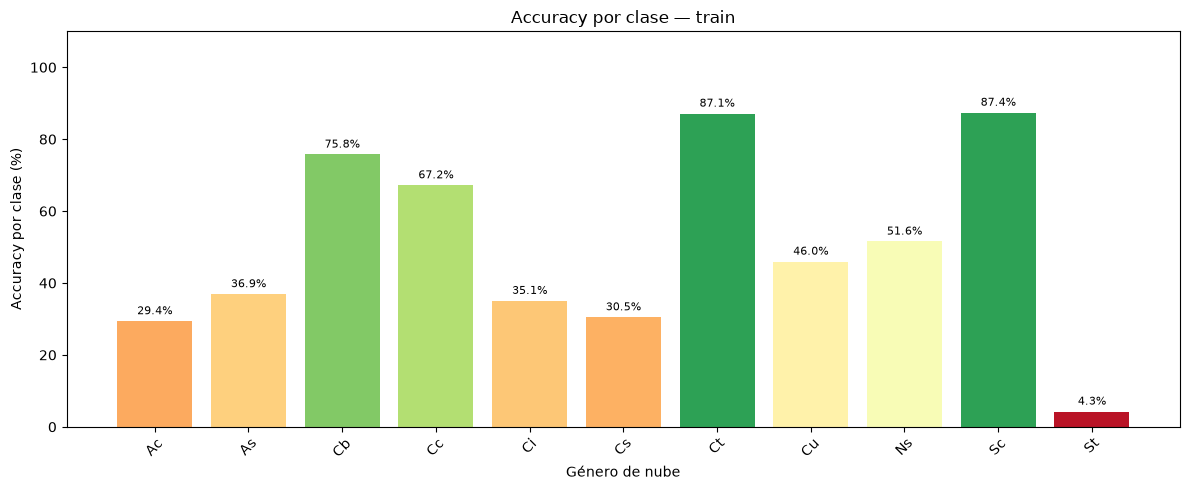

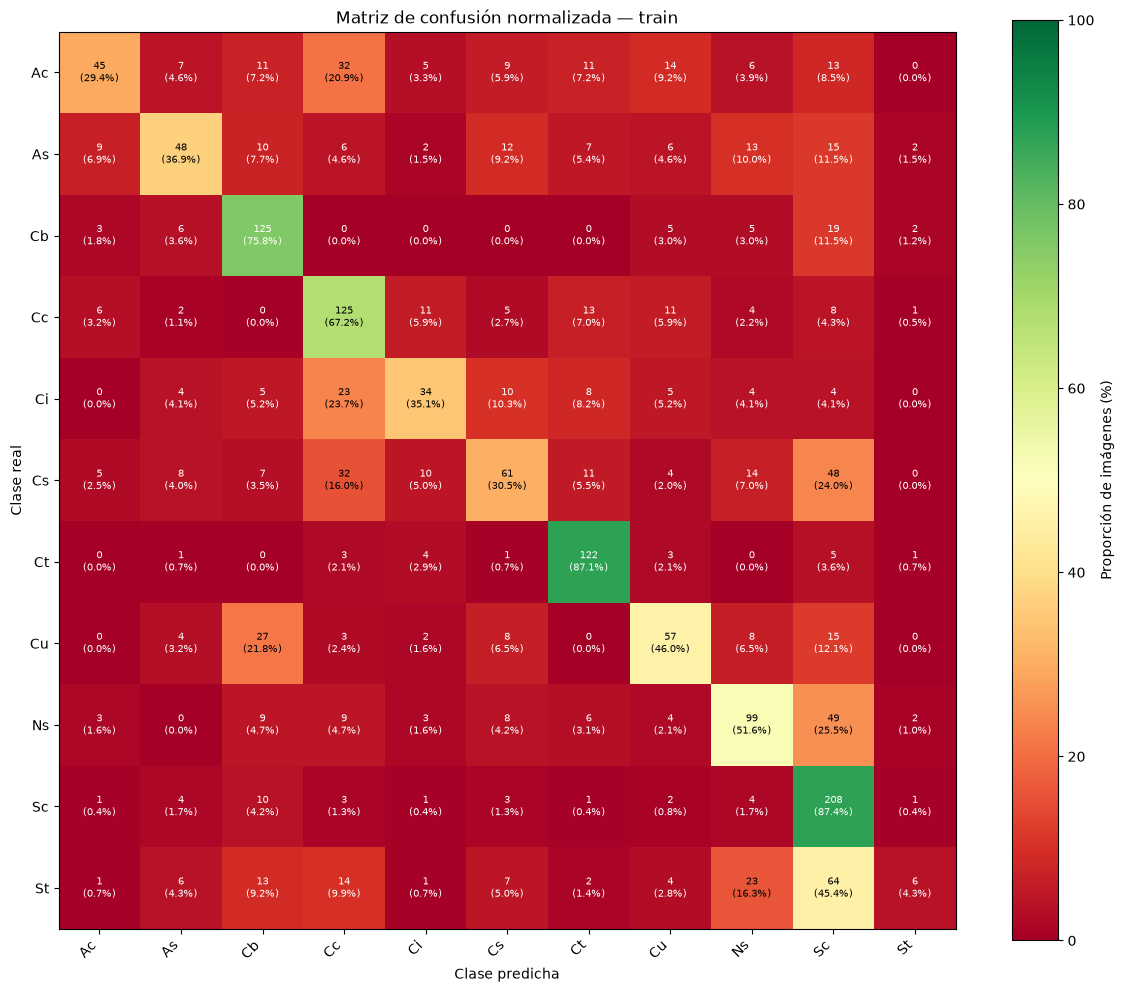


MÉTRICAS POR CLASE — VAL


,clase,muestras,aciertos,accuracy_clase,precision,recall,f1
0,Ac,33,6,18.18%,30.00%,18.18%,22.64%
1,As,28,4,14.29%,25.00%,14.29%,18.18%
2,Cb,35,13,37.14%,28.26%,37.14%,32.10%
3,Cc,39,26,66.67%,47.27%,66.67%,55.32%
4,Ci,21,6,28.57%,28.57%,28.57%,28.57%
5,Cs,43,12,27.91%,41.38%,27.91%,33.33%
6,Ct,30,15,50.00%,65.22%,50.00%,56.60%
7,Cu,27,8,29.63%,26.67%,29.63%,28.07%
8,Ns,41,15,36.59%,39.47%,36.59%,37.97%
9,Sc,51,35,68.63%,36.08%,68.63%,47.30%


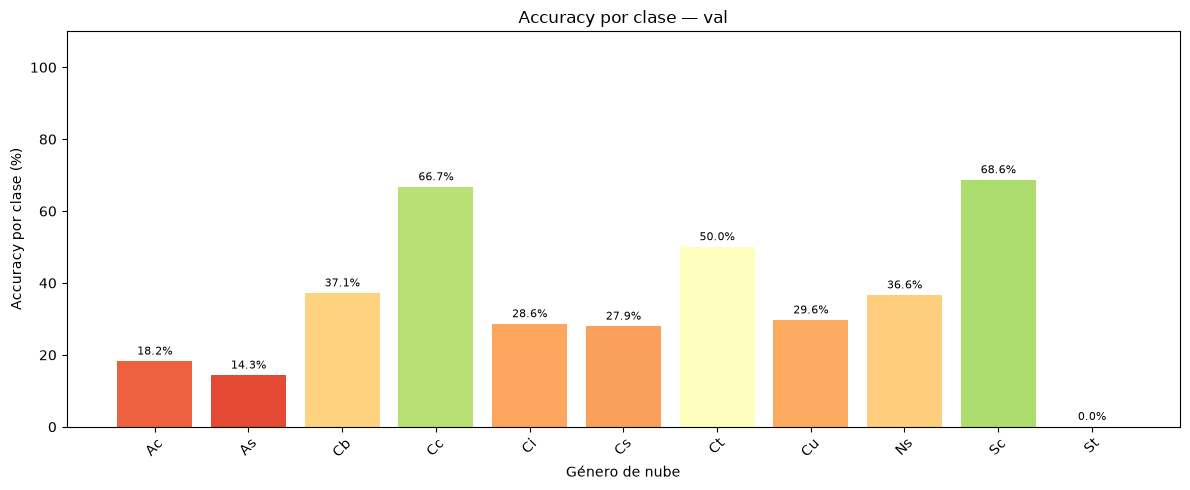

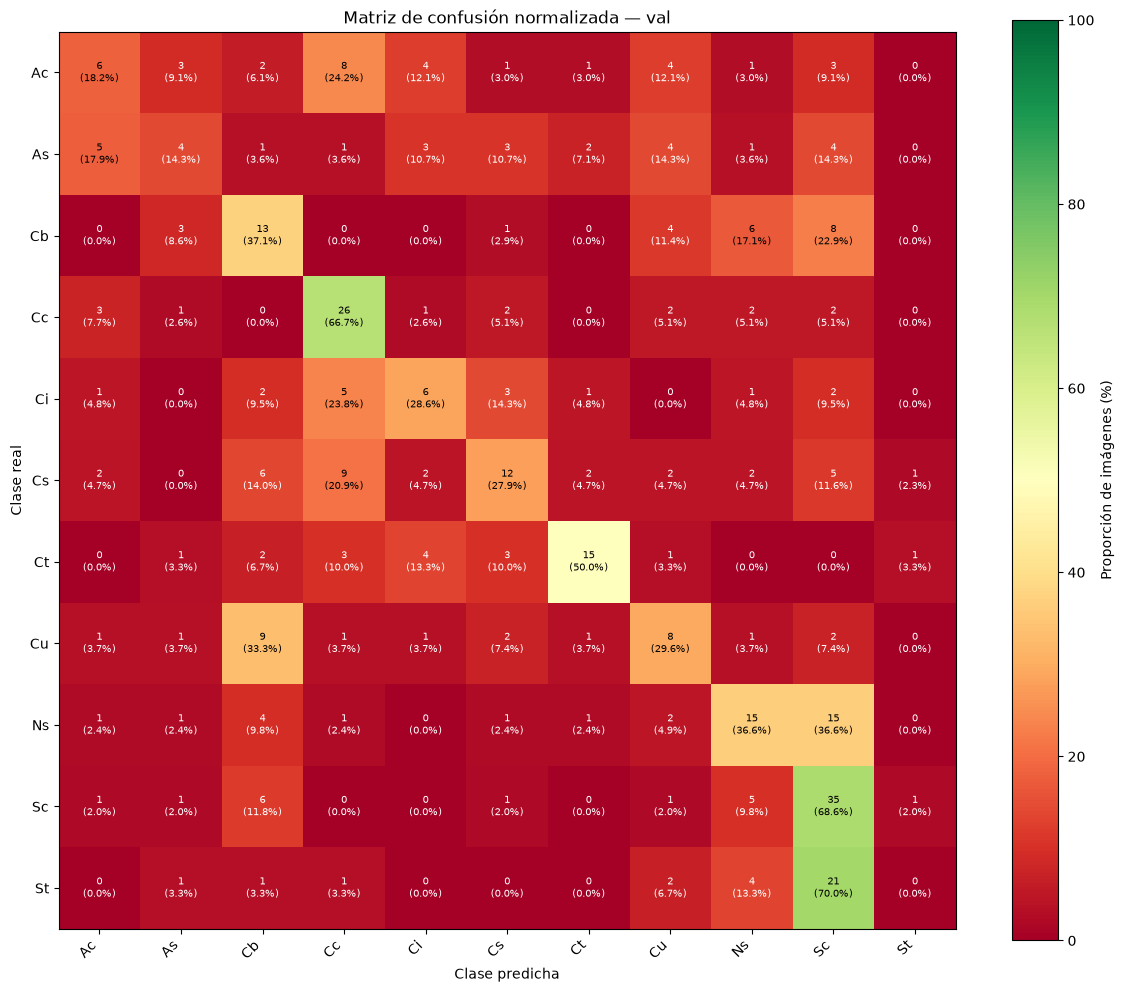


HISTORIAL DE ENTRENAMIENTO


,train_loss,train_acc,val_loss,val_acc,lr,epoch_time,best_epoch,best_val_loss
0,2.2631,0.1806,2.1281,0.2090,0.001,151.6724,19,1.799
1,2.1158,0.2310,2.0699,0.2196,0.001,127.0186,19,1.799
2,2.0596,0.2752,2.0667,0.2381,0.001,129.3590,19,1.799
3,2.0316,0.2763,1.9907,0.2937,0.001,126.2002,19,1.799
4,1.9641,0.3058,1.9833,0.3016,0.001,139.9130,19,1.799
5,1.9178,0.3313,1.9156,0.2963,0.001,137.4212,19,1.799
6,1.8703,0.3590,1.9217,0.3148,0.001,141.3542,19,1.799
7,1.8153,0.3539,1.8870,0.3228,0.001,139.8401,19,1.799
8,1.7808,0.3800,1.8262,0.3730,0.001,139.8479,19,1.799
9,1.7284,0.3986,1.9271,0.3228,0.001,140.1463,19,1.799


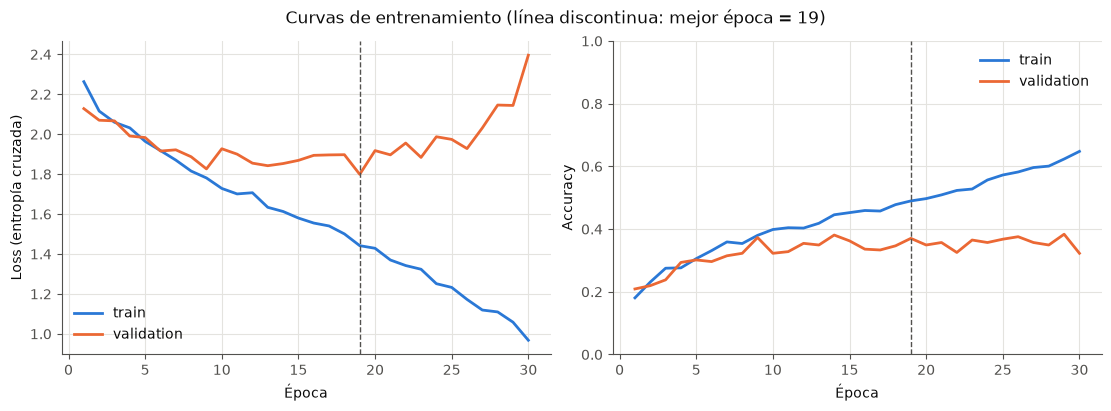


RESUMEN DEL EXPERIMENTO


,experimento,mejor_epoca,mejor_val_loss,train_accuracy,val_accuracy,generalization_gap
0,baseline,19,1.799,0.5266,0.3704,0.1562



Todos los archivos se guardaron en:
C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal\outputs\metricas\baseline


In [35]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from clouds_cnn.plots import (
    plot_confusion_matrix,
    plot_training_curves,
)

# Seleccionar el experimento entrenado.
resultado = resultado_baseline

# Crear la carpeta de resultados.
SALIDA = (
    Path(resultado.config.output_root)
    / "metricas"
    / resultado.config.run_name
)
SALIDA.mkdir(parents=True, exist_ok=True)

# Obtener las evaluaciones ya calculadas.
clases = list(resultado.class_names)

evaluaciones = {
    "train": resultado.train_eval.to_dict(clases),
    "val": resultado.val_eval.to_dict(clases),
}

# Construir las métricas generales.
filas_generales = []

for particion, evaluacion in evaluaciones.items():
    filas_generales.append({
        "particion": particion,
        "loss": evaluacion["loss"],
        "accuracy": evaluacion["accuracy"],
        "accuracy_%": evaluacion["accuracy"] * 100,
        "macro_f1": evaluacion["macro_f1"],
    })

tabla_general = pd.DataFrame(filas_generales)
tabla_general.to_csv(
    SALIDA / "metricas_generales.csv",
    index=False,
)

print("MÉTRICAS GENERALES")
display(
    tabla_general.style
    .format({
        "loss": "{:.4f}",
        "accuracy": "{:.2%}",
        "accuracy_%": "{:.2f}",
        "macro_f1": "{:.2%}",
    })
    .background_gradient(
        cmap="RdYlGn",
        subset=["accuracy", "macro_f1"],
        vmin=0,
        vmax=1,
    )
)

# Calcular las métricas por clase.
for particion, evaluacion in evaluaciones.items():

    matriz = np.asarray(
        evaluacion["confusion_matrix"],
        dtype=int,
    )

    assert matriz.shape == (len(clases), len(clases))

    soporte = matriz.sum(axis=1)
    aciertos = np.diag(matriz)

    accuracy_clase = np.divide(
        aciertos,
        soporte,
        out=np.zeros(len(clases), dtype=float),
        where=soporte != 0,
    )

    filas_clases = []

    for i, clase in enumerate(clases):
        valores = evaluacion["per_class"][clase]

        filas_clases.append({
            "clase": clase,
            "muestras": int(soporte[i]),
            "aciertos": int(aciertos[i]),
            "accuracy_clase": float(accuracy_clase[i]),
            "precision": valores["precision"],
            "recall": valores["recall"],
            "f1": valores["f1"],
        })

    tabla_clases = pd.DataFrame(filas_clases)

    # Guardar la tabla por clase.
    tabla_clases.to_csv(
        SALIDA / f"metricas_por_clase_{particion}.csv",
        index=False,
    )

    # 7. Mostrar la tabla coloreada.
    print(f"\nMÉTRICAS POR CLASE — {particion.upper()}")

    display(
        tabla_clases.style
        .format({
            "accuracy_clase": "{:.2%}",
            "precision": "{:.2%}",
            "recall": "{:.2%}",
            "f1": "{:.2%}",
        })
        .background_gradient(
            cmap="RdYlGn",
            subset=[
                "accuracy_clase",
                "precision",
                "recall",
                "f1",
            ],
            vmin=0,
            vmax=1,
        )
    )

    # Graficar el accuracy por clase.
    valores = tabla_clases["accuracy_clase"].to_numpy()
    colores = plt.get_cmap("RdYlGn")(valores)

    fig, ax = plt.subplots(figsize=(12, 5))

    barras = ax.bar(
        tabla_clases["clase"],
        valores * 100,
        color=colores,
    )

    ax.bar_label(
        barras,
        fmt="%.1f%%",
        padding=3,
        fontsize=8,
    )

    ax.set_ylim(0, 110)
    ax.set_ylabel("Accuracy por clase (%)")
    ax.set_xlabel("Género de nube")
    ax.set_title(f"Accuracy por clase — {particion}")
    ax.tick_params(axis="x", rotation=45)

    fig.tight_layout()
    fig.savefig(
        SALIDA / f"accuracy_por_clase_{particion}.png",
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    
    # Matriz de confusión coloreada.

    # Cada fila corresponde a una clase real.
    tabla_matriz = pd.DataFrame(
        matriz,
        index=clases,
        columns=clases,
    )
    tabla_matriz.index.name = "Clase real"

    # Guardar la matriz original con cantidades absolutas.
    tabla_matriz.to_csv(
        SALIDA / f"matriz_confusion_{particion}.csv"
    )

    # Normalizar por filas para obtener proporciones.
    totales = matriz.sum(axis=1, keepdims=True)

    matriz_normalizada = np.divide(
        matriz,
        totales,
        out=np.zeros_like(matriz, dtype=float),
        where=totales != 0,
    )

    # Guardar la matriz normalizada.
    pd.DataFrame(
        matriz_normalizada,
        index=clases,
        columns=clases,
    ).to_csv(
        SALIDA / f"matriz_confusion_normalizada_{particion}.csv"
    )

    # Crear gráfico con escala de colores.
    fig, ax = plt.subplots(figsize=(12, 10))

    imagen = ax.imshow(
        matriz_normalizada,
        cmap="RdYlGn",
        vmin=0,
        vmax=1,
    )

    ax.set_xticks(np.arange(len(clases)))
    ax.set_yticks(np.arange(len(clases)))

    ax.set_xticklabels(clases, rotation=45, ha="right")
    ax.set_yticklabels(clases)

    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(
        f"Matriz de confusión normalizada — {particion}"
    )

    # Mostrar cantidad de imágenes y porcentaje en cada celda.
    for i in range(len(clases)):
        for j in range(len(clases)):
            porcentaje = matriz_normalizada[i, j] * 100

            ax.text(
                j,
                i,
                f"{matriz[i, j]}\n({porcentaje:.1f}%)",
                ha="center",
                va="center",
                fontsize=7,
                color=(
                    "white"
                    if matriz_normalizada[i, j] >= 0.75
                    or matriz_normalizada[i, j] <= 0.15
                    else "black"
                ),
            )

    barra = fig.colorbar(imagen, ax=ax)
    barra.set_label("Proporción de imágenes (%)")
    barra.set_ticks(np.linspace(0, 1, 6))
    barra.set_ticklabels(["0", "20", "40", "60", "80", "100"])

    fig.tight_layout()

    fig.savefig(
        SALIDA / f"matriz_confusion_{particion}.png",
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

# Guardar el historial de entrenamiento.
historial = resultado.history

tabla_historial = pd.DataFrame(historial)
tabla_historial.to_csv(
    SALIDA / "historial_entrenamiento.csv",
    index=False,
)

print("\nHISTORIAL DE ENTRENAMIENTO")
display(tabla_historial.round(4))

# Visualizar las curvas de aprendizaje.
fig = plot_training_curves(historial)

fig.savefig(
    SALIDA / "curvas_entrenamiento.png",
    dpi=150,
    bbox_inches="tight",
)

display(fig)
plt.close(fig)

# Identificar la mejor época.
mejor_epoca = int(
    np.argmin(historial["val_loss"]) + 1
)

mejor_val_loss = float(
    np.min(historial["val_loss"])
)

# Crear el resumen final.
resumen = pd.DataFrame([{
    "experimento": resultado.config.run_name,
    "mejor_epoca": mejor_epoca,
    "mejor_val_loss": mejor_val_loss,
    "train_accuracy": evaluaciones["train"]["accuracy"],
    "val_accuracy": evaluaciones["val"]["accuracy"],
    "generalization_gap": resultado.generalization_gap,
}])

resumen.to_csv(
    SALIDA / "resumen_experimento.csv",
    index=False,
)

print("\nRESUMEN DEL EXPERIMENTO")
display(resumen.round(4))

print("\nTodos los archivos se guardaron en:")
print(SALIDA)


MÉTRICAS POR CLASE — TRAIN


,clase,soporte,aciertos,accuracy_clase,precision,recall,f1,ic_inferior,ic_superior
0,Ac,153,45,29.41%,61.64%,29.41%,39.82%,22.77%,37.06%
1,As,130,48,36.92%,53.33%,36.92%,43.64%,29.11%,45.48%
2,Cb,165,125,75.76%,57.60%,75.76%,65.45%,68.68%,81.66%
3,Cc,186,125,67.20%,50.00%,67.20%,57.34%,60.17%,73.54%
4,Ci,97,34,35.05%,46.58%,35.05%,40.00%,26.29%,44.95%
5,Cs,200,61,30.50%,49.19%,30.50%,37.65%,24.54%,37.20%
6,Ct,140,122,87.14%,67.40%,87.14%,76.01%,80.59%,91.71%
7,Cu,124,57,45.97%,49.57%,45.97%,47.70%,37.45%,54.73%
8,Ns,192,99,51.56%,55.00%,51.56%,53.23%,44.53%,58.53%
9,Sc,238,208,87.39%,46.43%,87.39%,60.64%,82.58%,91.03%


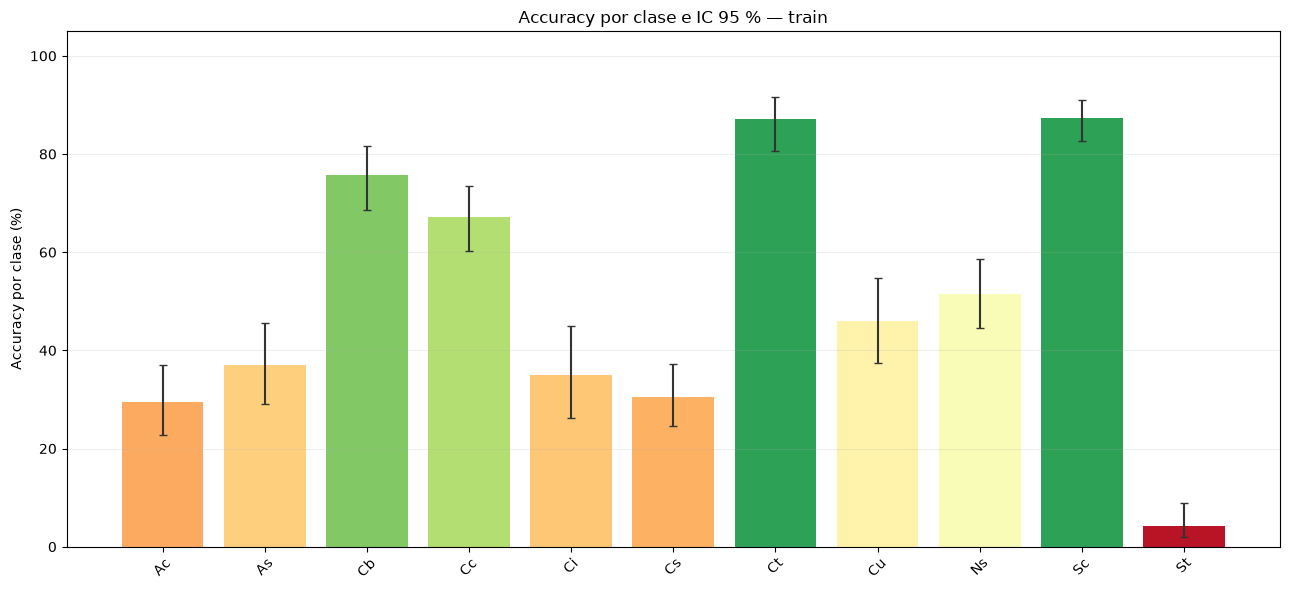

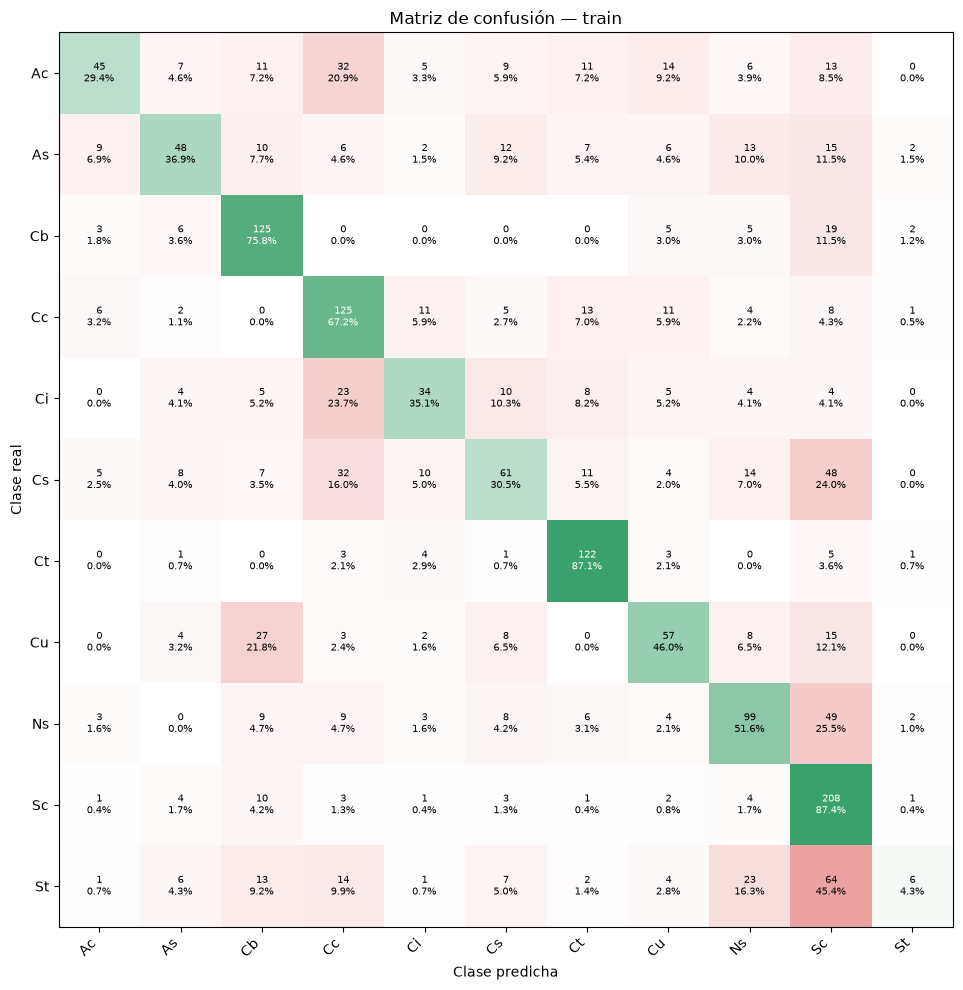


MÉTRICAS POR CLASE — VAL


,clase,soporte,aciertos,accuracy_clase,precision,recall,f1,ic_inferior,ic_superior
0,Ac,33,6,18.18%,30.00%,18.18%,22.64%,8.61%,34.39%
1,As,28,4,14.29%,25.00%,14.29%,18.18%,5.70%,31.49%
2,Cb,35,13,37.14%,28.26%,37.14%,32.10%,23.17%,53.66%
3,Cc,39,26,66.67%,47.27%,66.67%,55.32%,50.98%,79.37%
4,Ci,21,6,28.57%,28.57%,28.57%,28.57%,13.81%,49.96%
5,Cs,43,12,27.91%,41.38%,27.91%,33.33%,16.75%,42.69%
6,Ct,30,15,50.00%,65.22%,50.00%,56.60%,33.15%,66.85%
7,Cu,27,8,29.63%,26.67%,29.63%,28.07%,15.85%,48.48%
8,Ns,41,15,36.59%,39.47%,36.59%,37.97%,23.59%,51.88%
9,Sc,51,35,68.63%,36.08%,68.63%,47.30%,54.97%,79.67%


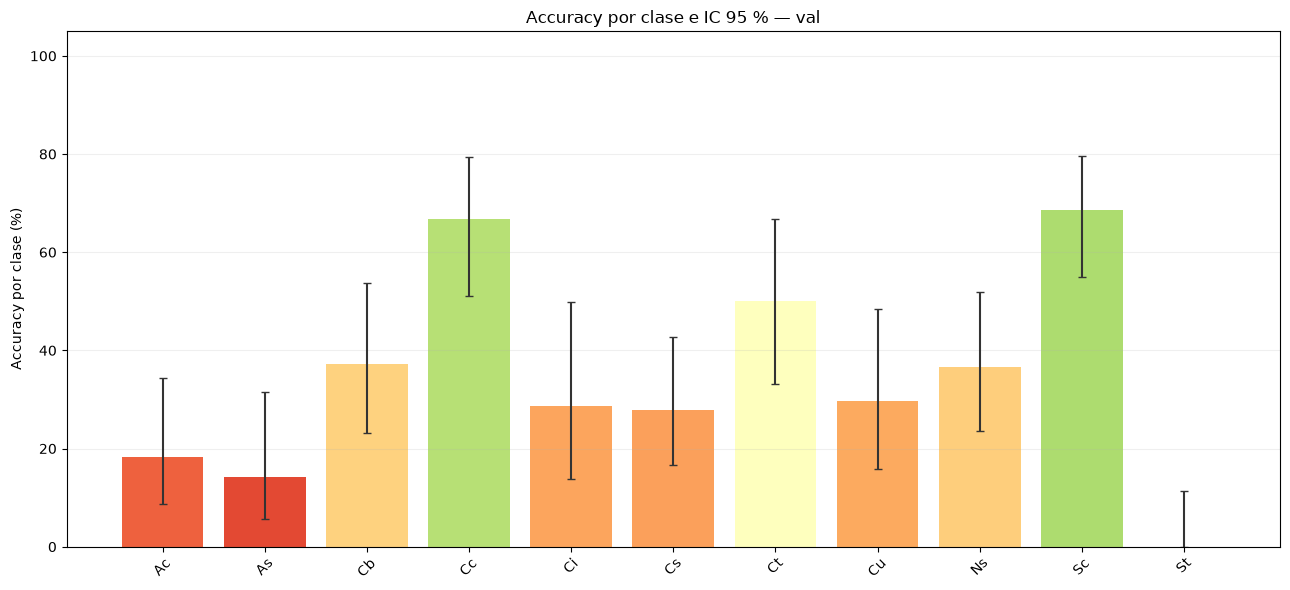

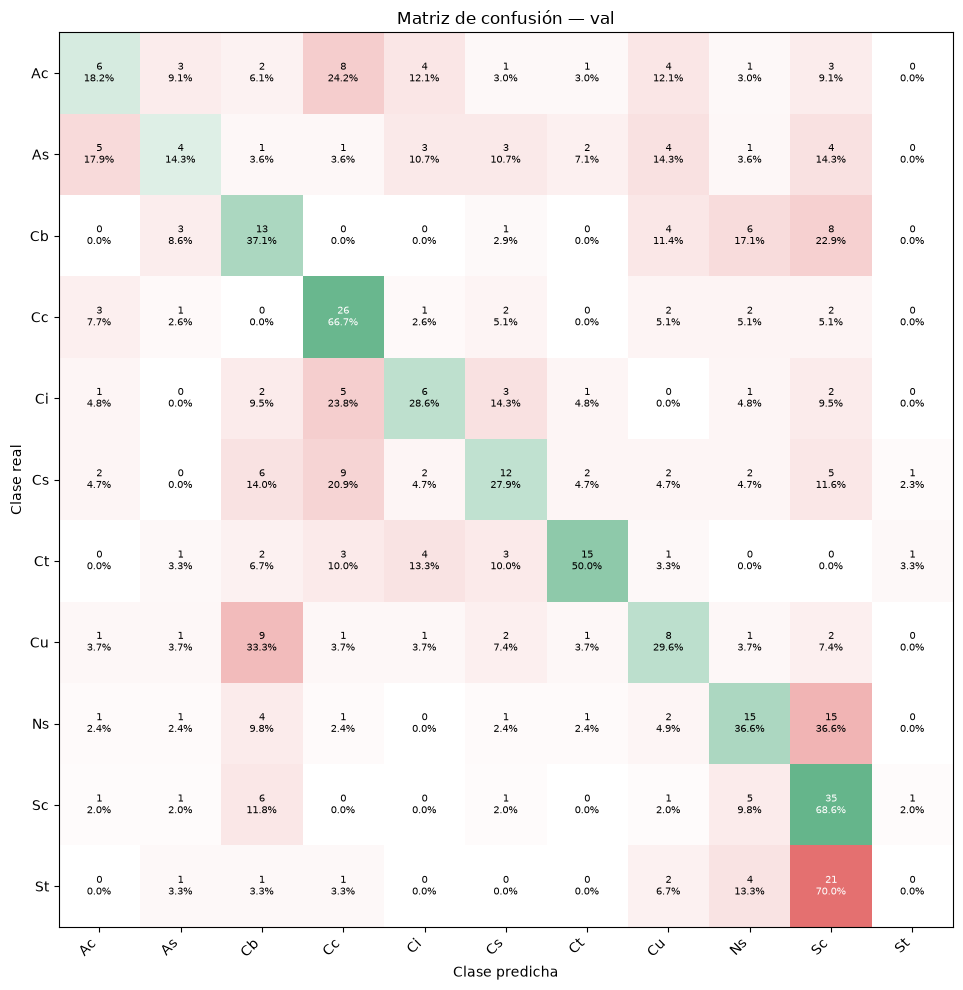


MÉTRICAS GENERALES


,particion,imagenes,aciertos,loss,accuracy,macro_f1,f1_ponderado,ic_inferior,ic_superior
0,train,1766,930,1.3620,52.66%,48.11%,49.23%,50.33%,54.98%
1,val,378,140,1.7990,37.04%,32.74%,34.38%,32.32%,42.01%



MEJOR ÉPOCA: 19
MEJOR VAL LOSS: 1.7989514870618386


,epoca,train_loss,val_loss,train_acc,val_acc
0,1,2.2631,2.1281,18.06%,20.90%
1,2,2.1158,2.0699,23.10%,21.96%
2,3,2.0596,2.0667,27.52%,23.81%
3,4,2.0316,1.9907,27.63%,29.37%
4,5,1.9641,1.9833,30.58%,30.16%
5,6,1.9178,1.9156,33.13%,29.63%
6,7,1.8703,1.9217,35.90%,31.48%
7,8,1.8153,1.8870,35.39%,32.28%
8,9,1.7808,1.8262,38.00%,37.30%
9,10,1.7284,1.9271,39.86%,32.28%


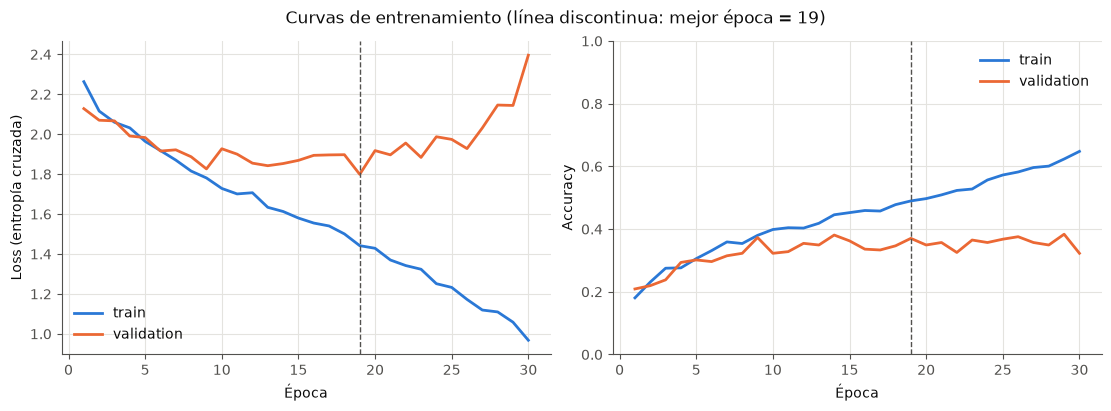

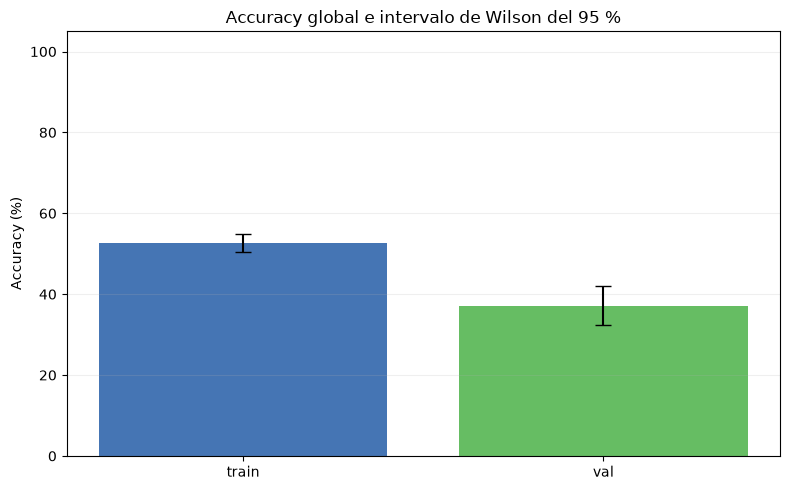


Archivos guardados en: C:\Users\Dany\Documents\Codigo de Matematicas cualquiera\Sistemas Inteligentes II\CNN-Nubes-Corte-II_FInal\outputs\metricas\baseline


In [37]:
import torch
from IPython.display import display

from clouds_cnn.plots import (
    plot_confusion_matrix,
    plot_training_curves,
)

# Resultados de la CNN ya entrenada.
resultado = resultado_baseline
clases = list(resultado.class_names)

SALIDA = (
    Path(resultado.config.output_root)
    / "metricas"
    / resultado.config.run_name
)
SALIDA.mkdir(parents=True, exist_ok=True)

evaluaciones = {
    "train": resultado.train_eval.to_dict(clases),
    "val": resultado.val_eval.to_dict(clases),
}

def intervalo_wilson(aciertos, total, z=1.96):
    """Intervalo de Wilson del 95 % para una proporción."""
    if total == 0:
        return np.nan, np.nan

    p = aciertos / total
    denominador = 1 + z**2 / total
    centro = (p + z**2 / (2 * total)) / denominador
    margen = (
        z
        * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2))
        / denominador
    )
    return centro - margen, centro + margen


def tabla_metricas_clase(evaluacion, nombres):
    """Calcula soporte, métricas e incertidumbre por clase."""
    matriz = np.asarray(evaluacion["confusion_matrix"])
    soporte = matriz.sum(axis=1)
    aciertos = np.diag(matriz)
    filas = []

    for i, clase in enumerate(nombres):
        valores = evaluacion["per_class"][clase]
        inferior, superior = intervalo_wilson(
            int(aciertos[i]),
            int(soporte[i]),
        )
        filas.append({
            "clase": clase,
            "soporte": int(soporte[i]),
            "aciertos": int(aciertos[i]),
            "accuracy_clase": valores["recall"],
            "precision": valores["precision"],
            "recall": valores["recall"],
            "f1": valores["f1"],
            "ic_inferior": inferior,
            "ic_superior": superior,
        })

    return pd.DataFrame(filas)


def grafico_accuracy(tabla, particion, destino):
    """Dibuja accuracy por clase e intervalos de confianza."""
    valores = tabla["accuracy_clase"].to_numpy()
    inferior = tabla["ic_inferior"].to_numpy()
    superior = tabla["ic_superior"].to_numpy()

    errores = np.vstack([
        np.maximum(valores - inferior, 0),
        np.maximum(superior - valores, 0),
    ]) * 100

    fig, ax = plt.subplots(figsize=(13, 6))
    colores = plt.get_cmap("RdYlGn")(valores)

    ax.bar(
        tabla["clase"],
        valores * 100,
        color=colores,
        yerr=errores,
        capsize=3,
        error_kw={"ecolor": "#333333"},
    )

    ax.set_ylim(0, 105)
    ax.set_ylabel("Accuracy por clase (%)")
    ax.set_title(
        f"Accuracy por clase e IC 95 % — {particion}"
    )
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.2)

    fig.tight_layout()
    fig.savefig(destino, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def grafico_confusion(matriz, nombres, particion, destino):
    """Muestra porcentajes por fila y aciertos/errores coloreados."""
    totales = matriz.sum(axis=1, keepdims=True)

    normalizada = np.divide(
        matriz,
        totales,
        out=np.zeros_like(matriz, dtype=float),
        where=totales != 0,
    )

    # Verde en la diagonal; rojo fuera de ella.
    colores = np.zeros((*matriz.shape, 3))
    colores[:] = [1.0, 1.0, 1.0]

    for i in range(len(nombres)):
        for j in range(len(nombres)):
            p = normalizada[i, j]
            base = (
                np.array([0.12, 0.58, 0.34])
                if i == j
                else np.array([0.85, 0.20, 0.20])
            )
            colores[i, j] = (1 - p) + p * base

    fig, ax = plt.subplots(figsize=(13, 10))
    ax.imshow(colores, vmin=0, vmax=1)

    ax.set_xticks(range(len(nombres)), nombres)
    ax.set_yticks(range(len(nombres)), nombres)
    ax.tick_params(axis="x", rotation=45)
    plt.setp(ax.get_xticklabels(), ha="right")

    for i in range(len(nombres)):
        for j in range(len(nombres)):
            p = normalizada[i, j]
            ax.text(
                j, i,
                f"{matriz[i, j]}\n{p:.1%}",
                ha="center",
                va="center",
                fontsize=7,
                color="white" if p >= 0.65 else "black",
            )

    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(f"Matriz de confusión — {particion}")

    fig.tight_layout()
    fig.savefig(destino, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    return normalizada


# Calcular métricas globales y por clase.
filas_generales = []

for particion, evaluacion in evaluaciones.items():
    tabla = tabla_metricas_clase(evaluacion, clases)
    matriz = np.asarray(
        evaluacion["confusion_matrix"],
        dtype=int,
    )

    soporte = tabla["soporte"].to_numpy()
    f1 = tabla["f1"].to_numpy()
    total = int(soporte.sum())
    aciertos = int(np.trace(matriz))

    f1_ponderado = (
        np.average(f1, weights=soporte)
        if total > 0 else np.nan
    )

    ic_global = intervalo_wilson(aciertos, total)

    filas_generales.append({
        "particion": particion,
        "imagenes": total,
        "aciertos": aciertos,
        "loss": evaluacion["loss"],
        "accuracy": evaluacion["accuracy"],
        "macro_f1": evaluacion["macro_f1"],
        "f1_ponderado": f1_ponderado,
        "ic_inferior": ic_global[0],
        "ic_superior": ic_global[1],
    })

    # Guardar métricas por clase.
    tabla.to_csv(
        SALIDA / f"metricas_por_clase_{particion}.csv",
        index=False,
    )

    print(f"\nMÉTRICAS POR CLASE — {particion.upper()}")

    display(
        tabla.style
        .format({
            "accuracy_clase": "{:.2%}",
            "precision": "{:.2%}",
            "recall": "{:.2%}",
            "f1": "{:.2%}",
            "ic_inferior": "{:.2%}",
            "ic_superior": "{:.2%}",
        })
        .background_gradient(
            cmap="RdYlGn",
            subset=[
                "accuracy_clase",
                "precision",
                "recall",
                "f1",
            ],
            vmin=0,
            vmax=1,
        )
        .background_gradient(
            cmap="Blues",
            subset=["soporte"],
        )
    )

    # Accuracy por clase con incertidumbre.
    grafico_accuracy(
        tabla,
        particion,
        SALIDA / f"accuracy_por_clase_{particion}.png",
    )

    # Guardar matriz de confusión absoluta.
    pd.DataFrame(
        matriz,
        index=clases,
        columns=clases,
    ).to_csv(
        SALIDA / f"matriz_confusion_{particion}.csv"
    )

    # Matriz de confusión coloreada.
    normalizada = grafico_confusion(
        matriz,
        clases,
        particion,
        SALIDA / f"matriz_confusion_{particion}.png",
    )

    # Guardar porcentajes de la matriz.
    pd.DataFrame(
        normalizada,
        index=clases,
        columns=clases,
    ).to_csv(
        SALIDA / f"matriz_normalizada_{particion}.csv"
    )

# Resumen general.
tabla_general = pd.DataFrame(filas_generales)

tabla_general.to_csv(
    SALIDA / "metricas_generales.csv",
    index=False,
)

print("\nMÉTRICAS GENERALES")
display(
    tabla_general.style
    .format({
        "loss": "{:.4f}",
        "accuracy": "{:.2%}",
        "macro_f1": "{:.2%}",
        "f1_ponderado": "{:.2%}",
        "ic_inferior": "{:.2%}",
        "ic_superior": "{:.2%}",
    })
    .background_gradient(
        cmap="RdYlGn",
        subset=["accuracy", "macro_f1", "f1_ponderado"],
        vmin=0,
        vmax=1,
    )
)

# Historial por época.
historial = resultado.history

tabla_historial = pd.DataFrame({
    "epoca": np.arange(1, len(historial["train_loss"]) + 1),
    "train_loss": historial["train_loss"],
    "val_loss": historial["val_loss"],
    "train_acc": historial["train_acc"],
    "val_acc": historial["val_acc"],
})

tabla_historial.to_csv(
    SALIDA / "historial_entrenamiento.csv",
    index=False,
)

mejor_epoca = int(historial["best_epoch"])
print("\nMEJOR ÉPOCA:", mejor_epoca)
print("MEJOR VAL LOSS:", historial["best_val_loss"])

display(
    tabla_historial.style
    .format({
        "train_loss": "{:.4f}",
        "val_loss": "{:.4f}",
        "train_acc": "{:.2%}",
        "val_acc": "{:.2%}",
    })
    .highlight_max(
        subset=["val_acc"],
        color="#b7e4c7",
    )
    .highlight_min(
        subset=["val_loss"],
        color="#b7e4c7",
    )
)

# Curvas del proyecto.
fig = plot_training_curves(historial)
fig.savefig(
    SALIDA / "curvas_entrenamiento.png",
    dpi=200,
    bbox_inches="tight",
)
display(fig)
plt.close(fig)

# Comparación de accuracy global con incertidumbre.
fig, ax = plt.subplots(figsize=(8, 5))

valores = tabla_general["accuracy"].to_numpy()
lim_inf = tabla_general["ic_inferior"].to_numpy()
lim_sup = tabla_general["ic_superior"].to_numpy()

errores = np.vstack([
    np.maximum(valores - lim_inf, 0),
    np.maximum(lim_sup - valores, 0),
]) * 100

ax.bar(
    tabla_general["particion"],
    valores * 100,
    color=["#4575b4", "#66bd63"],
    yerr=errores,
    capsize=6,
)

ax.set_ylim(0, 105)
ax.set_ylabel("Accuracy (%)")
ax.set_title("Accuracy global e intervalo de Wilson del 95 %")
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
fig.savefig(
    SALIDA / "comparacion_accuracy.png",
    dpi=200,
)
plt.show()
plt.close(fig)

print("\nArchivos guardados en:", SALIDA)


## 4. Seleccionar configuración y evaluar test UNA SOLA VEZ

Ejecuta esta celda únicamente cuando hayas terminado de seleccionar el modelo con validation. Si vuelves a experimentar, no uses las métricas de test para elegir parámetros.


In [ ]:
from clouds_cnn.experiment import evaluate_on_test

# Repite la definición aquí para que la celda sea ejecutable por separado.
results = {"baseline": resultado_baseline}
winner = max(
    results,
    key=lambda name: results[name].val_eval.report.macro_f1,
)
selected = results[winner]
print("Ganador según validation:", winner)
# Descomenta estas líneas solamente al cerrar la selección experimental:
# final_test = evaluate_on_test(selected.checkpoint_path, selected.config)
# print(final_test.to_dict())


## 5. Inspeccionar feature maps del mejor modelo

Se inspeccionan activaciones de la CNN, sin modificar sus pesos.


In [ ]:
import torch

device = get_device(selected.config.device_preference)
model = CloudCNN(
    num_classes=selected.config.num_classes,
    use_batchnorm=selected.config.use_batchnorm,
    dropout_p=selected.config.dropout_p,
).to(device)
checkpoint = torch.load(
    selected.checkpoint_path,
    map_location=device,
    weights_only=True,
)
model.load_state_dict(checkpoint["model_state_dict"])
val_loader = make_split_loader(selected.config, "val", device)
X, y = next(iter(val_loader))
feature_maps = capture_feature_maps(model, X[:1], "features.block4.act", device)
print("Feature maps:", feature_maps.shape)
